# Full CIFAR-10 training with a pure-NumPy CNN

This notebook trains a small CNN from scratch. Convolution uses vectorized
NumPy im2col/matrix multiplication; no deep-learning framework performs
model training or backpropagation.

The complete official training split is used. The official test split is
evaluated only after training. CIFAR-10 is fetched at runtime through Keras.

In [1]:
import gc
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

try:
    from tensorflow.keras.datasets import cifar10
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        'TensorFlow is required to fetch CIFAR-10. Install it with '
        '`pip install -e ".[datasets]"`.'
    ) from error

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "cifar10_baseline.json").is_file():
    PROJECT_ROOT = Path(
        r"C:\Users\hp\Documents\GitHub\visual-feature-learning"
    )

CONFIG_PATH = PROJECT_ROOT / "configs" / "cifar10_baseline.json"
with CONFIG_PATH.open(encoding="utf-8") as file:
    config = json.load(file)

dataset_config = config["dataset"]
training_config = config["training"]
class_names = dataset_config["class_names"]
num_classes = dataset_config["num_classes"]
seed = config["project"]["seed"]

assert dataset_config["name"] == "cifar10"
assert dataset_config["allow_subsampling"] is False
assert len(class_names) == num_classes

print("Project root:", PROJECT_ROOT)
print("Configuration:", CONFIG_PATH)
print("Training epochs:", training_config["epochs"])
print("Batch size:", training_config["batch_size"])

Project root: C:\Users\hp\Documents\GitHub\visual-feature-learning
Configuration: C:\Users\hp\Documents\GitHub\visual-feature-learning\configs\cifar10_baseline.json
Training epochs: 20
Batch size: 64


In [2]:
(train_images_raw, y_train_raw), (test_images_raw, y_test_raw) = cifar10.load_data()

y_train = y_train_raw.squeeze().astype(np.int64)
y_test = y_test_raw.squeeze().astype(np.int64)

assert train_images_raw.shape == (
    dataset_config["expected_train_samples"], 32, 32, 3
)
assert test_images_raw.shape == (
    dataset_config["expected_test_samples"], 32, 32, 3
)
assert y_train.shape == (50000,)
assert y_test.shape == (10000,)

normalization = dataset_config["normalization"]
mean = np.asarray(normalization["mean"], dtype=np.float32).reshape(1, 1, 1, 3)
std = np.asarray(normalization["std"], dtype=np.float32).reshape(1, 1, 1, 3)

# Scale pixels to [0, 1], normalize using configured channel statistics,
# then convert NHWC images to contiguous NCHW arrays.
x_train_nhwc = train_images_raw.astype(np.float32) / 255.0
x_test_nhwc = test_images_raw.astype(np.float32) / 255.0
x_train_nhwc = (x_train_nhwc - mean) / std
x_test_nhwc = (x_test_nhwc - mean) / std

x_train = np.ascontiguousarray(x_train_nhwc.transpose(0, 3, 1, 2))
x_test = np.ascontiguousarray(x_test_nhwc.transpose(0, 3, 1, 2))

del train_images_raw, test_images_raw, x_train_nhwc, x_test_nhwc
gc.collect()

assert x_train.shape == (50000, 3, 32, 32)
assert x_test.shape == (10000, 3, 32, 32)
assert x_train.dtype == np.float32
assert x_test.dtype == np.float32

print("Training arrays:", x_train.shape, y_train.shape)
print("Test arrays:    ", x_test.shape, y_test.shape)

Training arrays: (50000, 3, 32, 32) (50000,)
Test arrays:     (10000, 3, 32, 32) (10000,)


In [3]:
def convolution_padding(height, width, kernel_height, kernel_width, stride, padding):
    if padding == "valid":
        return 0, 0, 0, 0
    if padding != "same":
        raise ValueError("This notebook supports 'same' and 'valid' padding")

    output_height = (height + stride - 1) // stride
    output_width = (width + stride - 1) // stride
    total_height = max((output_height - 1) * stride + kernel_height - height, 0)
    total_width = max((output_width - 1) * stride + kernel_width - width, 0)

    top = total_height // 2
    left = total_width // 2
    return top, total_height - top, left, total_width - left


def im2col_nchw(x, kernel_size, stride=1, padding="valid"):
    """Extract NCHW image patches into a 2D matrix for convolution."""
    batch_size, channels, height, width = x.shape
    kernel_height, kernel_width = kernel_size

    pad_top, pad_bottom, pad_left, pad_right = convolution_padding(
        height, width, kernel_height, kernel_width, stride, padding
    )
    x_padded = np.pad(
        x,
        ((0, 0), (0, 0), (pad_top, pad_bottom), (pad_left, pad_right)),
    )

    windows = np.lib.stride_tricks.sliding_window_view(
        x_padded, (kernel_height, kernel_width), axis=(2, 3)
    )
    windows = windows[:, :, ::stride, ::stride]
    output_height, output_width = windows.shape[2:4]

    # Order each row as (channels, kernel_height, kernel_width).
    columns = windows.transpose(0, 2, 3, 1, 4, 5)
    columns = np.ascontiguousarray(
        columns.reshape(-1, channels * kernel_height * kernel_width)
    )
    cache = (
        x.shape,
        (pad_top, pad_bottom, pad_left, pad_right),
        (output_height, output_width),
        stride,
        kernel_size,
    )
    return columns, cache


def col2im_nchw(columns, cache):
    """Scatter convolution-column gradients back into an NCHW tensor."""
    input_shape, pads, output_shape, stride, kernel_size = cache
    batch_size, channels, height, width = input_shape
    output_height, output_width = output_shape
    kernel_height, kernel_width = kernel_size
    pad_top, pad_bottom, pad_left, pad_right = pads

    columns = columns.reshape(
        batch_size,
        output_height,
        output_width,
        channels,
        kernel_height,
        kernel_width,
    )
    columns = columns.transpose(0, 3, 1, 2, 4, 5)

    padded_height = height + pad_top + pad_bottom
    padded_width = width + pad_left + pad_right
    dx_padded = np.zeros(
        (batch_size, channels, padded_height, padded_width),
        dtype=columns.dtype,
    )

    for kernel_y in range(kernel_height):
        for kernel_x in range(kernel_width):
            dx_padded[
                :,
                :,
                kernel_y : kernel_y + output_height * stride : stride,
                kernel_x : kernel_x + output_width * stride : stride,
            ] += columns[:, :, :, :, kernel_y, kernel_x]

    return dx_padded[
        :,
        :,
        pad_top : pad_top + height,
        pad_left : pad_left + width,
    ]


class Conv2D:
    def __init__(self, in_channels, out_channels, kernel_size, rng, padding="same"):
        self.kernel_size = (kernel_size, kernel_size)
        self.stride = 1
        self.padding = padding

        fan_in = in_channels * kernel_size * kernel_size
        self.weights = (
            rng.standard_normal((out_channels, fan_in)).astype(np.float32)
            * np.sqrt(2.0 / fan_in)
        )
        self.bias = np.zeros(out_channels, dtype=np.float32)
        self.velocity_weights = np.zeros_like(self.weights)
        self.velocity_bias = np.zeros_like(self.bias)

    def forward(self, x):
        columns, self._cache = im2col_nchw(
            x, self.kernel_size, self.stride, self.padding
        )
        output_height, output_width = self._cache[2]
        batch_size = x.shape[0]
        output_channels = self.weights.shape[0]

        output = columns @ self.weights.T + self.bias
        output = output.reshape(batch_size, output_height, output_width, output_channels)
        return output.transpose(0, 3, 1, 2)

    def backward(self, d_output):
        batch_size, output_channels, output_height, output_width = d_output.shape
        d_output_rows = d_output.transpose(0, 2, 3, 1).reshape(-1, output_channels)

        columns, _ = im2col_nchw_from_cache(self._cache)
        d_weights = d_output_rows.T @ columns
        d_bias = d_output_rows.sum(axis=0)
        d_columns = d_output_rows @ self.weights

        d_x = col2im_nchw(d_columns, self._cache)
        return d_x, d_weights, d_bias

    def update(self, d_weights, d_bias, learning_rate, momentum, weight_decay):
        self.velocity_weights *= momentum
        self.velocity_weights += d_weights + weight_decay * self.weights
        self.weights -= learning_rate * self.velocity_weights

        self.velocity_bias *= momentum
        self.velocity_bias += d_bias
        self.bias -= learning_rate * self.velocity_bias


def im2col_nchw_from_cache(cache):
    """Reconstruct the columns needed by Conv2D backward from its input cache."""
    # The layer stores columns separately during forward to avoid rebuilding
    # input patches during every backward pass.
    return cache["columns"], cache["geometry"]

In [4]:
# Replace Conv2D.forward/backward with versions that retain the columns.
def conv2d_forward(self, x):
    columns, geometry = im2col_nchw(
        x, self.kernel_size, self.stride, self.padding
    )
    output_height, output_width = geometry[2]
    batch_size = x.shape[0]
    output_channels = self.weights.shape[0]

    output = columns @ self.weights.T + self.bias
    output = output.reshape(batch_size, output_height, output_width, output_channels)
    self._cache = {"columns": columns, "geometry": geometry}
    return output.transpose(0, 3, 1, 2)


def conv2d_backward(self, d_output):
    _, output_channels, _, _ = d_output.shape
    d_output_rows = d_output.transpose(0, 2, 3, 1).reshape(-1, output_channels)

    columns = self._cache["columns"]
    geometry = self._cache["geometry"]
    d_weights = d_output_rows.T @ columns
    d_bias = d_output_rows.sum(axis=0)
    d_columns = d_output_rows @ self.weights

    d_x = col2im_nchw(d_columns, geometry)
    return d_x, d_weights, d_bias


Conv2D.forward = conv2d_forward
Conv2D.backward = conv2d_backward


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return np.maximum(x, 0)

    def backward(self, d_output):
        return d_output * self.mask


class MaxPool2D:
    def __init__(self, pool_size=2, stride=2):
        self.pool_size = pool_size
        self.stride = stride

    def forward(self, x):
        windows = np.lib.stride_tricks.sliding_window_view(
            x, (self.pool_size, self.pool_size), axis=(2, 3)
        )
        windows = windows[:, :, ::self.stride, ::self.stride]
        batch, channels, out_h, out_w = windows.shape[:4]
        windows = windows.reshape(batch, channels, out_h, out_w, -1)

        self.argmax = windows.argmax(axis=-1)
        self.input_shape = x.shape
        self.output_shape = (batch, channels, out_h, out_w)
        return np.take_along_axis(
            windows, self.argmax[..., None], axis=-1
        )[..., 0]

    def backward(self, d_output):
        if d_output.shape != self.output_shape:
            raise ValueError("MaxPool2D gradient shape mismatch")

        batch, channels, out_h, out_w = self.output_shape
        d_x = np.zeros(self.input_shape, dtype=d_output.dtype)

        for flat_index in range(self.pool_size * self.pool_size):
            offset_y, offset_x = divmod(flat_index, self.pool_size)
            mask = self.argmax == flat_index
            d_x[
                :,
                :,
                offset_y : offset_y + out_h * self.stride : self.stride,
                offset_x : offset_x + out_w * self.stride : self.stride,
            ] += d_output * mask

        return d_x


class Dense:
    def __init__(self, in_features, out_features, rng):
        self.weights = (
            rng.standard_normal((out_features, in_features)).astype(np.float32)
            * np.sqrt(2.0 / in_features)
        )
        self.bias = np.zeros(out_features, dtype=np.float32)
        self.velocity_weights = np.zeros_like(self.weights)
        self.velocity_bias = np.zeros_like(self.bias)

    def forward(self, x):
        self.input = x
        return x @ self.weights.T + self.bias

    def backward(self, d_output):
        d_weights = d_output.T @ self.input
        d_bias = d_output.sum(axis=0)
        d_x = d_output @ self.weights
        return d_x, d_weights, d_bias

    def update(self, d_weights, d_bias, learning_rate, momentum, weight_decay):
        self.velocity_weights *= momentum
        self.velocity_weights += d_weights + weight_decay * self.weights
        self.weights -= learning_rate * self.velocity_weights

        self.velocity_bias *= momentum
        self.velocity_bias += d_bias
        self.bias -= learning_rate * self.velocity_bias


def cross_entropy_with_logits(logits, labels):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    probabilities = exp_scores / exp_scores.sum(axis=1, keepdims=True)

    batch_indices = np.arange(labels.shape[0])
    loss = -np.log(probabilities[batch_indices, labels] + 1e-12).mean()

    d_logits = probabilities
    d_logits[batch_indices, labels] -= 1.0
    d_logits /= labels.shape[0]
    return float(loss), d_logits


class CIFAR10CNN:
    def __init__(self, rng):
        self.conv1 = Conv2D(3, 16, 3, rng, padding="same")
        self.relu1 = ReLU()
        self.pool1 = MaxPool2D(2, 2)
        self.conv2 = Conv2D(16, 32, 3, rng, padding="same")
        self.relu2 = ReLU()
        self.pool2 = MaxPool2D(2, 2)

        # 32x32 -> pool -> 16x16 -> pool -> 8x8.
        self.flattened_features = 32 * 8 * 8
        self.dense = Dense(self.flattened_features, num_classes, rng)

    def forward(self, x):
        x = self.conv1.forward(x)
        x = self.relu1.forward(x)
        x = self.pool1.forward(x)

        x = self.conv2.forward(x)
        x = self.relu2.forward(x)
        x = self.pool2.forward(x)

        self.flatten_shape = x.shape
        x = x.reshape(x.shape[0], -1)
        return self.dense.forward(x)

    def backward(self, d_logits):
        d_x, d_weights, d_bias = self.dense.backward(d_logits)
        dense_gradients = (d_weights, d_bias)
        d_x = d_x.reshape(self.flatten_shape)

        d_x = self.pool2.backward(d_x)
        d_x = self.relu2.backward(d_x)
        d_x, conv2_weights, conv2_bias = self.conv2.backward(d_x)

        d_x = self.pool1.backward(d_x)
        d_x = self.relu1.backward(d_x)
        _, conv1_weights, conv1_bias = self.conv1.backward(d_x)

        return {
            "conv1": (conv1_weights, conv1_bias),
            "conv2": (conv2_weights, conv2_bias),
            "dense": dense_gradients,
        }

    def update(self, gradients, learning_rate, momentum, weight_decay):
        self.conv1.update(*gradients["conv1"], learning_rate, momentum, weight_decay)
        self.conv2.update(*gradients["conv2"], learning_rate, momentum, weight_decay)
        self.dense.update(*gradients["dense"], learning_rate, momentum, weight_decay)

    def parameter_count(self):
        return sum(
            layer.weights.size + layer.bias.size
            for layer in (self.conv1, self.conv2, self.dense)
        )

In [5]:
rng = np.random.default_rng(seed)
model = CIFAR10CNN(rng)

sample_logits = model.forward(x_train[:2])
assert sample_logits.shape == (2, num_classes)
assert model.flattened_features == 2048

configured_dense = next(
    layer for layer in config["model"]["layers"] if layer["type"] == "dense"
)
if configured_dense["in_features"] != model.flattened_features:
    print(
        "Config correction needed: set model.layers[dense].in_features to",
        model.flattened_features,
    )

loss, d_logits = cross_entropy_with_logits(
    sample_logits.copy(),
    y_train[:2],
)
gradients = model.backward(d_logits)

assert np.isfinite(loss)
assert all(
    np.all(np.isfinite(gradient))
    for pair in gradients.values()
    for gradient in pair
)

print("Logits shape:", sample_logits.shape)
print("Flattened features:", model.flattened_features)
print("Trainable parameters:", f"{model.parameter_count():,}")
print("Forward/backward smoke check: OK")

Config correction needed: set model.layers[dense].in_features to 2048
Logits shape: (2, 10)
Flattened features: 2048
Trainable parameters: 25,578
Forward/backward smoke check: OK


In [6]:
def train_one_epoch(
    model,
    x,
    y,
    batch_size,
    learning_rate,
    momentum,
    weight_decay,
    rng,
    horizontal_flip,
    log_every,
):
    order = rng.permutation(len(x))
    total_loss = 0.0
    total_correct = 0
    start_time = time.time()

    for batch_number, start in enumerate(range(0, len(x), batch_size), start=1):
        indices = order[start : start + batch_size]
        batch_x = x[indices].copy()
        batch_y = y[indices]

        if horizontal_flip:
            flip_mask = rng.random(len(batch_x)) < 0.5
            batch_x[flip_mask] = batch_x[flip_mask, :, :, ::-1]

        logits = model.forward(batch_x)
        loss, d_logits = cross_entropy_with_logits(logits, batch_y)
        gradients = model.backward(d_logits)
        model.update(gradients, learning_rate, momentum, weight_decay)

        total_loss += loss * len(batch_y)
        total_correct += int(np.sum(logits.argmax(axis=1) == batch_y))

        if log_every and batch_number % log_every == 0:
            print(
                f"  batch {batch_number:>4}/{(len(x) + batch_size - 1) // batch_size} "
                f"- loss {total_loss / (start + len(batch_y)):.4f}"
            )

    return {
        "loss": total_loss / len(x),
        "accuracy": total_correct / len(x),
        "seconds": time.time() - start_time,
    }


def evaluate(model, x, y, batch_size, num_classes):
    total_loss = 0.0
    total_correct = 0
    confusion = np.zeros((num_classes, num_classes), dtype=np.int64)

    for start in range(0, len(x), batch_size):
        batch_x = x[start : start + batch_size]
        batch_y = y[start : start + batch_size]
        logits = model.forward(batch_x)
        loss, _ = cross_entropy_with_logits(logits.copy(), batch_y)
        predictions = logits.argmax(axis=1)

        total_loss += loss * len(batch_y)
        total_correct += int(np.sum(predictions == batch_y))
        confusion += np.bincount(
            batch_y * num_classes + predictions,
            minlength=num_classes * num_classes,
        ).reshape(num_classes, num_classes)

    return {
        "loss": total_loss / len(x),
        "accuracy": total_correct / len(x),
        "confusion_matrix": confusion,
    }

In [7]:
rng = np.random.default_rng(seed)
model = CIFAR10CNN(rng)

optimizer_config = training_config["optimizer"]
schedule_config = training_config["learning_rate_schedule"]
milestones = set(schedule_config["milestones"])

history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "learning_rate": [],
    "seconds": [],
}

output_dir = PROJECT_ROOT / config["artifacts"]["output_dir"]
checkpoint_dir = PROJECT_ROOT / config["artifacts"]["checkpoint_dir"]
output_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

learning_rate = optimizer_config["learning_rate"]
epochs = training_config["epochs"]
batch_size = training_config["batch_size"]

print(f"Training samples per epoch: {len(x_train):,}")
print(f"Total epochs: {epochs}")
print(f"Batch size: {batch_size}")
print(f"Parameters: {model.parameter_count():,}")

for epoch in range(1, epochs + 1):
    epoch_result = train_one_epoch(
        model=model,
        x=x_train,
        y=y_train,
        batch_size=batch_size,
        learning_rate=learning_rate,
        momentum=optimizer_config["momentum"],
        weight_decay=optimizer_config["weight_decay"],
        rng=rng,
        horizontal_flip=dataset_config["augmentation"]["horizontal_flip"],
        log_every=training_config["log_every_n_batches"],
    )

    history["epoch"].append(epoch)
    history["train_loss"].append(epoch_result["loss"])
    history["train_accuracy"].append(epoch_result["accuracy"])
    history["learning_rate"].append(learning_rate)
    history["seconds"].append(epoch_result["seconds"])

    print(
        f"Epoch {epoch:02d}/{epochs} | "
        f"loss {epoch_result['loss']:.4f} | "
        f"accuracy {epoch_result['accuracy']:.2%} | "
        f"lr {learning_rate:g} | "
        f"{epoch_result['seconds'] / 60:.1f} min"
    )

    # Save model weights and history after every epoch.
    np.savez(
        checkpoint_dir / "cifar10_cnn_latest.npz",
        conv1_weights=model.conv1.weights,
        conv1_bias=model.conv1.bias,
        conv2_weights=model.conv2.weights,
        conv2_bias=model.conv2.bias,
        dense_weights=model.dense.weights,
        dense_bias=model.dense.bias,
    )
    with (output_dir / "training_history.json").open("w", encoding="utf-8") as file:
        json.dump(history, file, indent=2)

    if epoch in milestones:
        learning_rate *= schedule_config["gamma"]

print("Training complete.")

Training samples per epoch: 50,000
Total epochs: 20
Batch size: 64
Parameters: 25,578
  batch  100/782 - loss 1.8513
  batch  200/782 - loss 1.6843
  batch  300/782 - loss 1.5953
  batch  400/782 - loss 1.5285
  batch  500/782 - loss 1.4817
  batch  600/782 - loss 1.4400
  batch  700/782 - loss 1.4031
Epoch 01/20 | loss 1.3795 | accuracy 51.03% | lr 0.01 | 3.0 min
  batch  100/782 - loss 1.1280
  batch  200/782 - loss 1.1173
  batch  300/782 - loss 1.1040
  batch  400/782 - loss 1.0976
  batch  500/782 - loss 1.0939
  batch  600/782 - loss 1.0890
  batch  700/782 - loss 1.0825
Epoch 02/20 | loss 1.0786 | accuracy 62.50% | lr 0.01 | 3.2 min
  batch  100/782 - loss 1.0001
  batch  200/782 - loss 1.0076
  batch  300/782 - loss 0.9901
  batch  400/782 - loss 0.9951
  batch  500/782 - loss 0.9835
  batch  600/782 - loss 0.9810
  batch  700/782 - loss 0.9829
Epoch 03/20 | loss 0.9794 | accuracy 66.03% | lr 0.01 | 3.1 min
  batch  100/782 - loss 0.9178
  batch  200/782 - loss 0.9063
  batch  

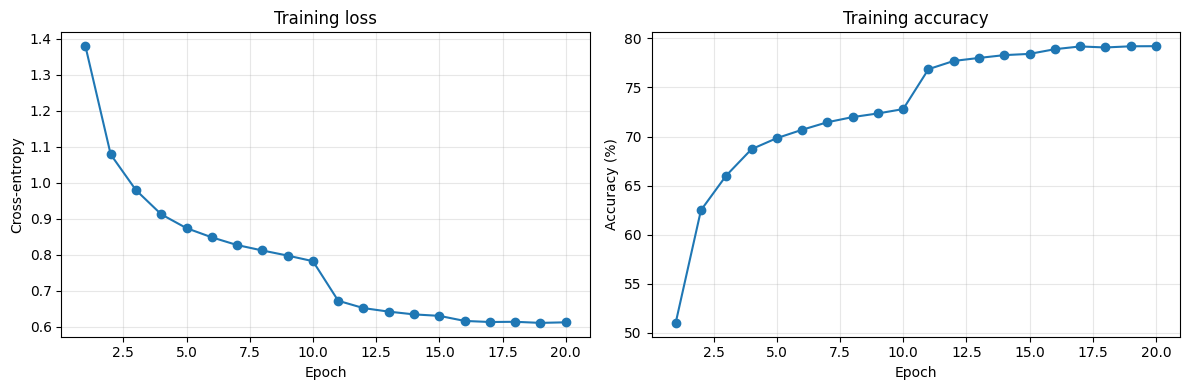

In [8]:
epochs_seen = history["epoch"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_seen, history["train_loss"], marker="o")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs_seen,
    np.asarray(history["train_accuracy"]) * 100,
    marker="o",
)
axes[1].set_title("Training accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [9]:
test_result = evaluate(
    model=model,
    x=x_test,
    y=y_test,
    batch_size=batch_size,
    num_classes=num_classes,
)

confusion = test_result["confusion_matrix"]
per_class_accuracy = confusion.diagonal() / confusion.sum(axis=1)

print(f"Test loss:     {test_result['loss']:.4f}")
print(f"Test accuracy: {test_result['accuracy']:.2%}")
print("\nPer-class test accuracy:")
for name, accuracy in zip(class_names, per_class_accuracy):
    print(f"  {name:>10}: {accuracy:.2%}")

metrics = {
    "test_loss": test_result["loss"],
    "test_accuracy": test_result["accuracy"],
    "per_class_accuracy": {
        name: float(accuracy)
        for name, accuracy in zip(class_names, per_class_accuracy)
    },
    "confusion_matrix": confusion.tolist(),
    "train_samples": len(x_train),
    "test_samples": len(x_test),
    "epochs": epochs,
    "batch_size": batch_size,
    "parameter_count": model.parameter_count(),
}

metrics_path = output_dir / "final_metrics.json"
with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

print("\nSaved metrics to:", metrics_path)

Test loss:     0.7945
Test accuracy: 73.48%

Per-class test accuracy:
    airplane: 75.80%
  automobile: 83.40%
        bird: 60.70%
         cat: 55.30%
        deer: 70.40%
         dog: 65.40%
        frog: 80.90%
       horse: 77.60%
        ship: 82.80%
       truck: 82.50%

Saved metrics to: C:\Users\hp\Documents\GitHub\visual-feature-learning\outputs\cifar10_baseline\final_metrics.json


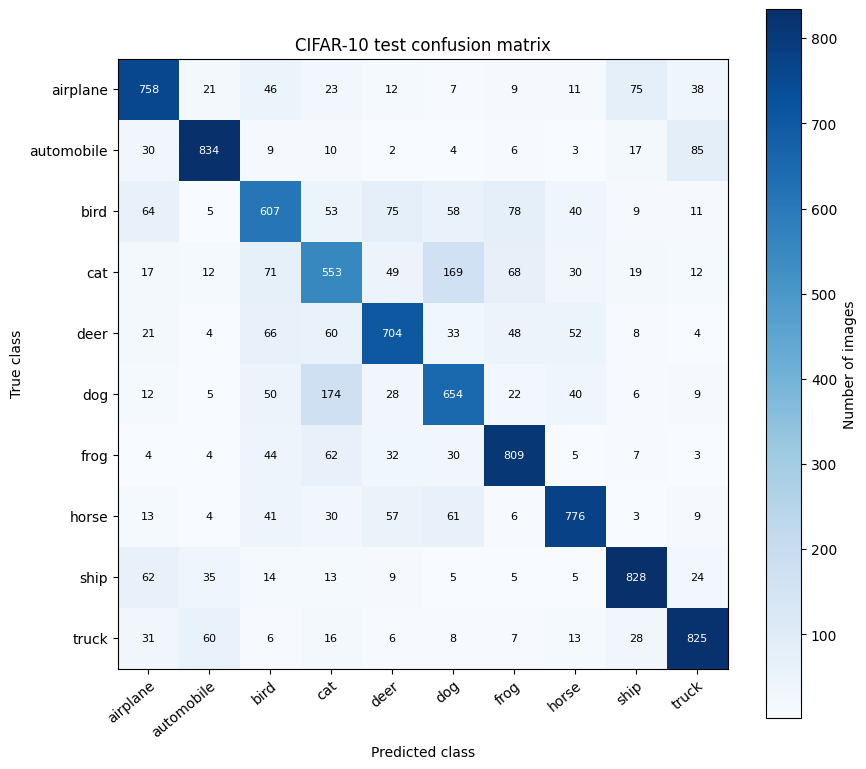

In [10]:
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(confusion, cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of images")

ax.set(
    xticks=np.arange(num_classes),
    yticks=np.arange(num_classes),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="CIFAR-10 test confusion matrix",
)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")

threshold = confusion.max() / 2
for row in range(num_classes):
    for column in range(num_classes):
        ax.text(
            column,
            row,
            f"{confusion[row, column]}",
            ha="center",
            va="center",
            color="white" if confusion[row, column] > threshold else "black",
            fontsize=8,
        )

fig.tight_layout()
plt.show()